# Retail Analytics: where is the retailer losing profit?

Group mini-project (Data Analytics part). This notebook cleans the Sample Superstore data, measures where profit is lost, tests why, and sizes the opportunity. The cleaning and the loss-driver steps reuse the code in `src/`, so they give the same numbers as `python run_pipeline.py`.

**Research questions**
- **Main question (strategic):** Where is the retailer losing profit, and what should it fix first?
- **Supporting question 1 (descriptive):** Which stores, countries and product categories have the lowest profit margins?
- **Supporting question 2 (diagnostic):** Why are these areas underperforming? (e.g., high discounts, many returns, or customers unhappy with price, service or availability)
- **Supporting question 3 (recommendation-oriented):** Which actions would recover the most profit, and which should the retailer do first?

**Contents**
1. Setup
2. Load and validate the raw data
3. Clean and prepare the data
4. Overview: size of the problem
5. Where are margins lowest? (supporting question 1)
6. Why? Discounts (supporting question 2)
7. Strongest loss drivers, with uncertainty (main question)
8. Sizing the discount lever (supporting question 3)
9. Limitations
10. Summary of key findings

**How to run:** from the project root, put `sample_-_superstore.csv` in the `DATA/` folder, then choose *Restart & Run All*.

## 1. Setup

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import etl, loss_drivers
from src.utils import HIGH_DISCOUNT, load_data, money

# the src modules select a file-only plotting backend when imported,
# so the inline backend is switched on again after the imports
%matplotlib inline

# progress messages (INFO, with file paths) go only to output/logs/pipeline.log; warnings still show here
for handler in logging.getLogger("pipeline").handlers:
    if type(handler) is logging.StreamHandler:
        handler.setLevel(logging.WARNING)

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
NEGATIVE, POSITIVE, NEUTRAL = "#c0392b", "#2a6f97", "#b0b7c0"


def colors(values):
    """Red for negative values, blue for positive ones."""
    return [NEGATIVE if v < 0 else POSITIVE for v in values]

## 2. Load and validate the raw data

`etl.load_raw_data()` reads the raw CSV and stops with a clear error if any required column is missing.

In [2]:
raw = etl.load_raw_data()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head(3)

10,194 rows x 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,01/03/2023,01/07/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.45,2,0.20,5.55
1,2,US-2023-112326,01/04/2023,01/08/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.54,2,0.80,-5.49
2,3,US-2023-112326,01/04/2023,01/08/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.78,3,0.20,4.27


In [3]:
before = etl.quality_check(raw, "(before cleaning)")
print("Data-quality findings in the raw file:")
print("\n".join(f"- {issue}" for issue in before["issues"]))

2026-11-22 11:08:48 | WARNING  | etl                | Date columns require conversion: Order Date, Ship Date
Data-quality findings in the raw file:
- No missing values detected.
- No duplicate rows detected.
- Date columns require conversion: Order Date, Ship Date


## 3. Clean and prepare the data

`etl.clean_data` applies these rules, in this order: drop rows with missing values, convert the date columns, drop duplicate rows, strip spaces from text columns, and drop rows with negative sales or quantity. Rows with negative **profit** are kept, because they are what we are analysing. `etl.add_columns` then creates `Product Cost = Sales - Profit`.

First, how many rows each rule can affect (a row can match more than one rule):

In [4]:
pd.Series({
    "Rows with missing values": raw.isna().any(axis=1).sum(),
    "Duplicate rows": raw.duplicated().sum(),
    "Rows with negative sales or quantity": ((raw["Sales"] < 0) | (raw["Quantity"] < 0)).sum(),
}, name="rows affected").to_frame()

,rows affected
Rows with missing values,0
Duplicate rows,0
Rows with negative sales or quantity,0


In [5]:
clean = etl.add_columns(etl.clean_data(raw))
after = etl.quality_check(clean, "(after cleaning)")
print(f"{len(raw) - len(clean):,} rows removed by the cleaning rules.")

display(pd.DataFrame({
    "before cleaning": [before["rows"], before["duplicates"], len(before["missing"])],
    "after cleaning": [after["rows"], after["duplicates"], len(after["missing"])],
}, index=["rows", "duplicate rows", "columns with missing values"]))

display(pd.DataFrame({
    "before": raw[etl.DATE_COLUMNS].dtypes.astype(str),
    "after": clean[etl.DATE_COLUMNS].dtypes.astype(str),
}).rename_axis("date column"))

print("Data-quality findings after cleaning:")
print("\n".join(f"- {issue}" for issue in after["issues"]))

0 rows removed by the cleaning rules.


,before cleaning,after cleaning
rows,10194,10194
duplicate rows,0,0
columns with missing values,0,0


,before,after
date column,,
Order Date,object,datetime64[ns]
Ship Date,object,datetime64[ns]


Data-quality findings after cleaning:
- No missing values detected.
- No duplicate rows detected.


Next, the cleaned file is saved (it is the input of the other scripts) and loaded back. `load_data()` adds the columns used in several analyses (`Year`, `Quarter`, `YearMonth`, `Ship Days` and `Discount Range`), and `add_loss_columns` adds the ones used by the loss analysis (`is_loss`, `loss`, `deep_discount`).

In [6]:
etl.save_data(clean)
df = loss_drivers.add_loss_columns(load_data())
df[["Order Date", "Category", "Sales", "Discount", "Profit", "Product Cost", "Discount Range", "is_loss"]].head()

,Order Date,Category,Sales,Discount,Profit,Product Cost,Discount Range,is_loss
0,2023-01-03,Office Supplies,16.45,0.20,5.55,10.90,1-20%,False
1,2023-01-04,Office Supplies,3.54,0.80,-5.49,9.03,>40%,True
2,2023-01-04,Office Supplies,11.78,0.20,4.27,7.51,1-20%,False
3,2023-01-04,Office Supplies,272.74,0.20,-64.77,337.51,1-20%,True
4,2023-01-05,Office Supplies,19.54,0.20,4.88,14.65,1-20%,False


## 4. Overview: size of the problem

Each row of the data is an order line. *Gross loss* is the sum of the negative profits only, and *gross gain* is the sum of the positive profits.

In [7]:
sales, profit = df["Sales"].sum(), df["Profit"].sum()
gross_gain = df.loc[df["Profit"] > 0, "Profit"].sum()
gross_loss = df.loc[df["Profit"] < 0, "Profit"].sum()

pd.Series({
    "Total sales": money(sales),
    "Total profit": money(profit),
    "Profit margin": f"{profit / sales:.2%}",
    "Order lines": f"{len(df):,}",
    "Order lines that lose money": f"{df['is_loss'].mean():.1%}",
    "Gross loss": money(gross_loss),
    "Gross loss as % of gross gain": f"{-gross_loss / gross_gain:.0%}",
}, name="value").to_frame()

,value
Total sales,"$2,327K"
Total profit,$292K
Profit margin,12.56%
Order lines,"10,194"
Order lines that lose money,18.6%
Gross loss,-$157K
Gross loss as % of gross gain,35%


## 5. Where are margins lowest? (supporting question 1)

The dataset has **no store column**, so the closest levels are used: category, region, state/province and country. *Profit margin* = total profit ÷ total sales.

,sales,profit,lines,margin_pct
Category,,,,
Furniture,"754,747.76","19,730.00",2201,2.61
Office Supplies,"731,893.31","126,023.44",6128,17.22
Technology,"839,893.28","146,543.38",1865,17.45


Lowest margin: Furniture (2.6%). Highest: Technology (17.4%).


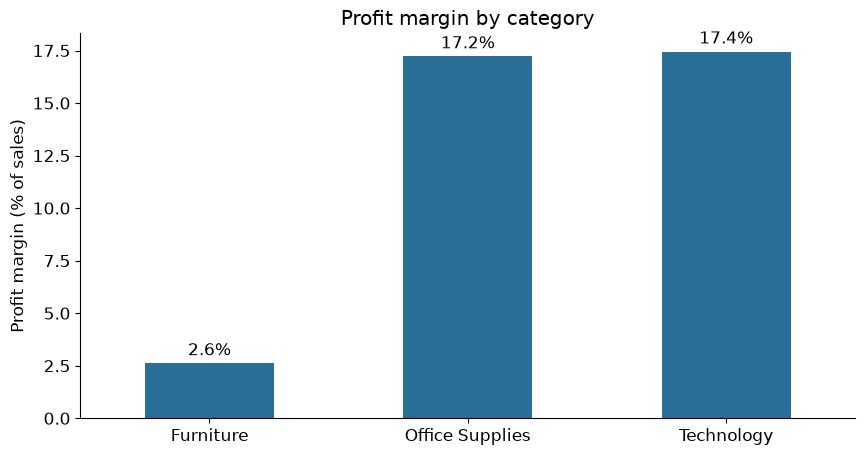

In [8]:
def margin_table(by):
    """Sales, profit and margin for any grouping, from the lowest margin to the highest."""
    t = df.groupby(by).agg(sales=("Sales", "sum"), profit=("Profit", "sum"), lines=("Sales", "size"))
    t["margin_pct"] = t["profit"] / t["sales"] * 100
    return t.sort_values("margin_pct")


cat = margin_table("Category")
display(cat)
print(f"Lowest margin: {cat.index[0]} ({cat['margin_pct'].iloc[0]:.1f}%). Highest: {cat.index[-1]} ({cat['margin_pct'].iloc[-1]:.1f}%).")

ax = cat["margin_pct"].plot.bar(color=colors(cat["margin_pct"]), rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(title="Profit margin by category", xlabel="", ylabel="Profit margin (% of sales)")
plt.show()

3 of 17 sub-categories lose money overall: Supplies, Bookcases, Tables (-$23K combined).


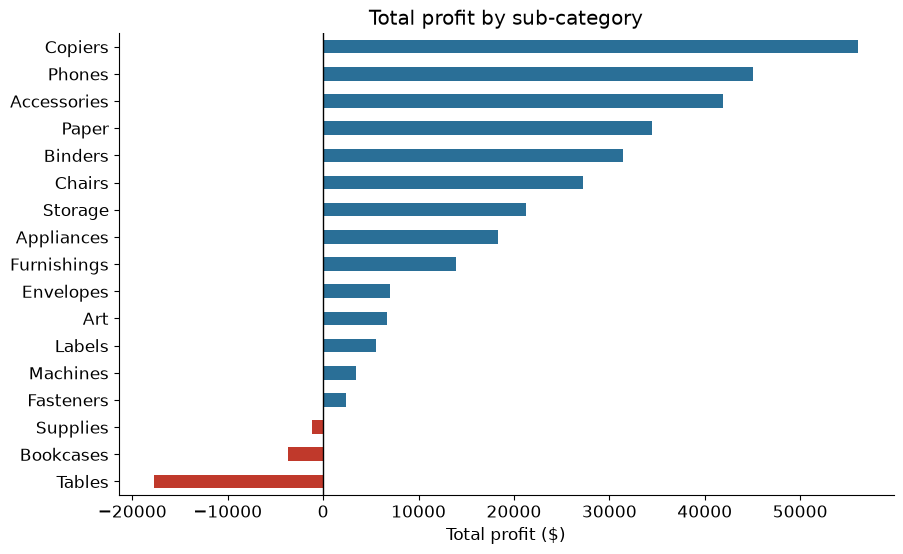

In [9]:
sub = df.groupby("Sub-Category")["Profit"].sum().sort_values()
negative = sub[sub < 0]
print(f"{len(negative)} of {len(sub)} sub-categories lose money overall: {', '.join(negative.index[::-1])} ({money(negative.sum())} combined).")

ax = sub.plot.barh(color=colors(sub), figsize=(10, 6))
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Total profit by sub-category", xlabel="Total profit ($)", ylabel="")
plt.show()

,sales,profit,lines,margin_pct
Region,,,,
Central,"503,170.67","39,865.31",2335,7.92
South,"391,721.90","46,749.43",1620,11.93
East,"691,828.17","94,883.26",2986,13.71
West,"739,813.61","110,798.82",3253,14.98


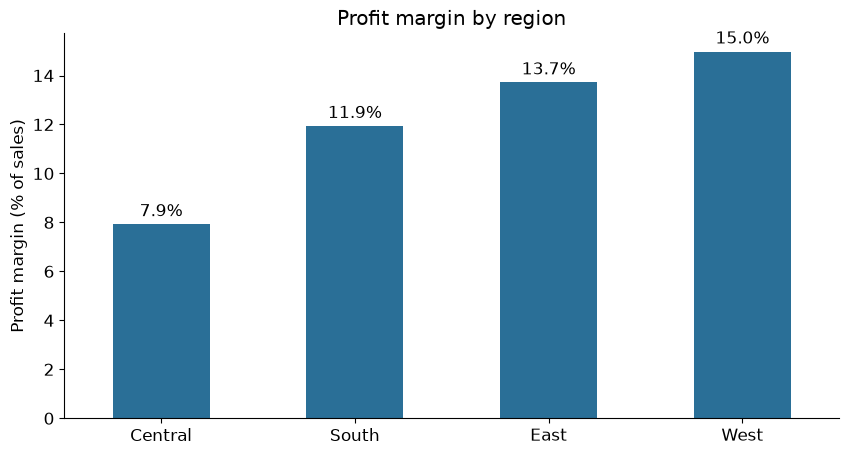

In [10]:
region = margin_table("Region")
display(region)

ax = region["margin_pct"].plot.bar(color=colors(region["margin_pct"]), rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(title="Profit margin by region", xlabel="", ylabel="Profit margin (% of sales)")
plt.show()

37 states/provinces with fewer than 100 order lines are left out (too small to compare).


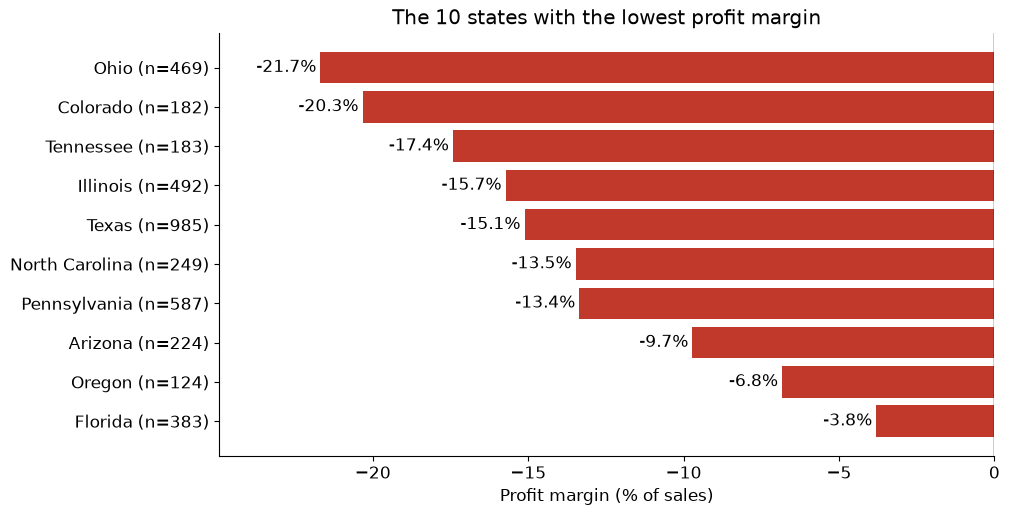

In [11]:
states_all = margin_table("State/Province")
states = states_all[states_all["lines"] >= loss_drivers.MIN_ROWS].head(10)
left_out = (states_all["lines"] < loss_drivers.MIN_ROWS).sum()
print(f"{left_out} states/provinces with fewer than {loss_drivers.MIN_ROWS} order lines are left out (too small to compare).")

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh([f"{s} (n={n:,})" for s, n in zip(states.index, states["lines"])],
               states["margin_pct"], color=colors(states["margin_pct"]))
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=1)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.margins(x=0.15)
ax.set(title="The 10 states with the lowest profit margin", xlabel="Profit margin (% of sales)")
plt.show()

In [12]:
# only two countries exist in the data; Canada is a small sample
margin_table("Country/Region")

,sales,profit,lines,margin_pct
Country/Region,,,,
United States,"2,297,200.86","286,397.02",9994,12.47
Canada,"29,333.49","5,899.79",200,20.11


## 6. Why? Discounts (supporting question 2)

Discount is the main factor in the data that can explain losses. Returns and customer satisfaction are not in the dataset (see the limitations). The discount ranges come from `src/utils.py`, so they always agree with `HIGH_DISCOUNT`.

,lines,sales,profit,gross_loss,margin_pct,row_share_pct,loss_share_pct
Discount Range,,,,,,,
0%,4925,"1,105,323.79","326,718.59",0.00,29.56,48.31,-0.00
1-20%,3854,"856,450.41","101,598.91","-17,879.06",11.86,37.81,11.39
21-40%,464,"235,465.28","-35,990.96","-39,130.14",-15.29,4.55,24.92
>40%,951,"129,294.87","-100,029.73","-100,029.73",-77.37,9.33,63.70


Lines with a discount above 20%: 13.9% of the lines, 88.6% of the gross loss, margin -37.3%.


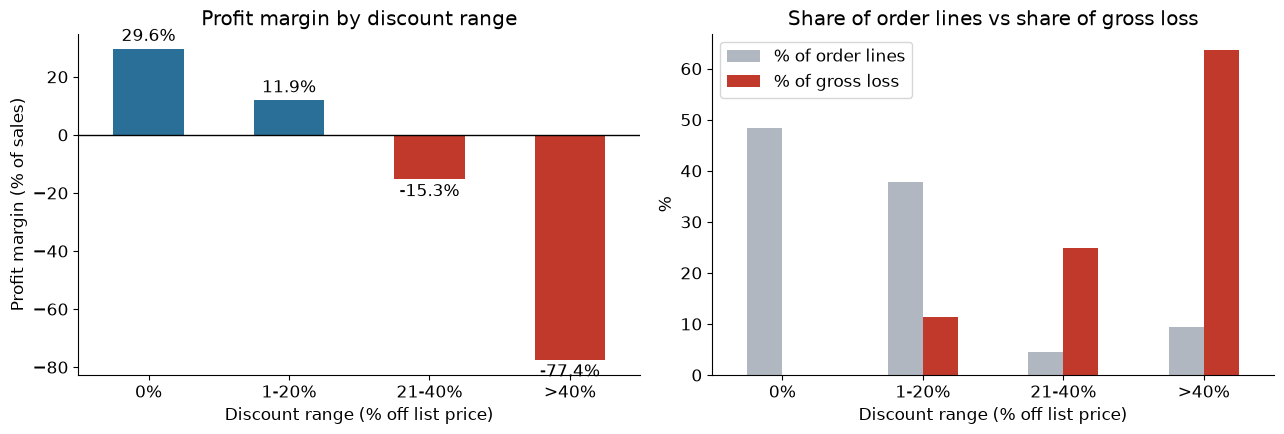

In [13]:
rng = df.groupby("Discount Range", observed=True).agg(
    lines=("Sales", "size"), sales=("Sales", "sum"), profit=("Profit", "sum"), gross_loss=("loss", "sum")
)
rng["margin_pct"] = rng["profit"] / rng["sales"] * 100
rng["row_share_pct"] = rng["lines"] / rng["lines"].sum() * 100
rng["loss_share_pct"] = rng["gross_loss"] / rng["gross_loss"].sum() * 100
display(rng)

deep = df[df["deep_discount"]]
print(f"Lines with a discount above {HIGH_DISCOUNT:.0%}: {len(deep) / len(df):.1%} of the lines, "
      f"{deep['loss'].sum() / df['loss'].sum():.1%} of the gross loss, margin {deep['Profit'].sum() / deep['Sales'].sum():.1%}.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rng["margin_pct"].plot.bar(ax=axes[0], color=colors(rng["margin_pct"]), rot=0)
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=3)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(title="Profit margin by discount range", xlabel="Discount range (% off list price)", ylabel="Profit margin (% of sales)")
rng[["row_share_pct", "loss_share_pct"]].plot.bar(ax=axes[1], color=[NEUTRAL, NEGATIVE], rot=0)
axes[1].set(title="Share of order lines vs share of gross loss", xlabel="Discount range (% off list price)", ylabel="%")
axes[1].legend(["% of order lines", "% of gross loss"])
fig.tight_layout()
plt.show()

Does the conclusion depend on where "deep discount" starts? The table shows the same measures for other cut-off points (`discount_above` = the discount a line must exceed).

In [14]:
loss_drivers.threshold_sensitivity(df)

,rows_pct,loss_share_pct,loss_rate_pct,margin_pct
discount_above,,,,
0.00,51.69,100.00,36.08,-2.82
0.10,50.75,99.98,36.67,-3.73
0.20,13.88,88.61,96.82,-37.29
0.30,11.62,81.66,97.81,-48.22
0.40,9.33,63.70,100.00,-77.37
0.50,8.57,49.05,100.00,-118.71


## 7. Strongest loss drivers, with uncertainty (main question)

**Step 1 – screening.** Each candidate dimension is ranked by how much of the variation in row-level loss it explains (adjusted eta-squared, which does not favour dimensions with many groups). The values are small in absolute terms because losses are skewed (many rows have zero loss), so use them only to rank the dimensions.

,groups,eta2,adj_eta2
dimension,,,
Discount Band,4,0.07,0.07
Sub-Category,17,0.07,0.06
State/Province,59,0.02,0.01
Category,3,0.00,0.00
Region,4,0.00,0.00
Country/Region,2,0.00,0.00
Ship Mode,4,0.00,-0.00
Segment,3,0.00,-0.00
Year,4,0.00,-0.00


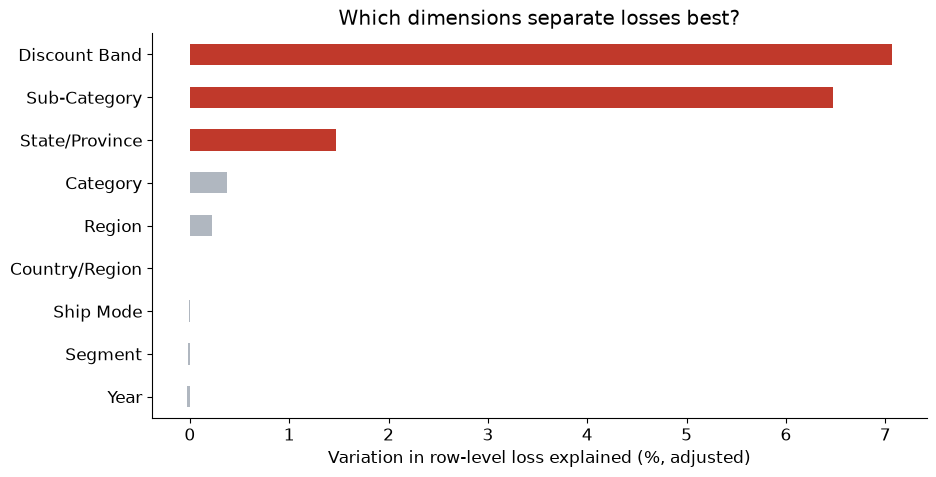

In [15]:
ranking = loss_drivers.screen_dimensions(df)
display(ranking)

r = ranking["adj_eta2"].mul(100).sort_values()
ax = r.plot.barh(color=[NEGATIVE if i >= len(r) - loss_drivers.N_DRIVERS else NEUTRAL for i in range(len(r))])
ax.set(title="Which dimensions separate losses best?", xlabel="Variation in row-level loss explained (%, adjusted)", ylabel="")
plt.show()

**Step 2 – the top drivers.** The top dimensions become drivers. For the non-discount ones, the "hot" groups are the fewest groups that together cover 60% of the gross loss. Intervals are 95% bootstrap intervals that resample whole orders, because lines of the same order are not independent.

,row_share_pct,loss_share_pct,loss_share_lo,loss_share_hi,loss_rate_group_pct,loss_rate_elsewhere_pct
driver,,,,,,
Deep discount (>20%),13.88,88.61,85.48,90.99,96.82,6.05
"Sub-Category: Binders, Tables, Machines",19.53,64.43,58.13,69.97,43.60,12.59
"State/Province: Texas, Ohio, Pennsylvania, Illinois",24.85,63.47,55.44,71.04,48.48,8.78


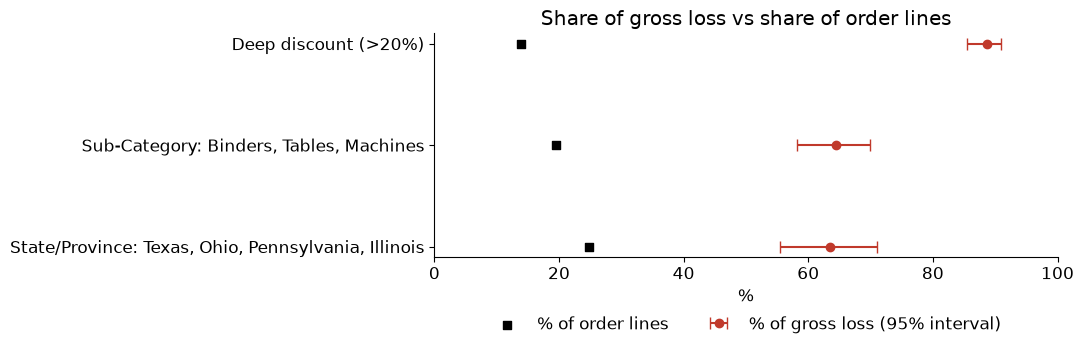

In [16]:
drivers = loss_drivers.build_drivers(df, ranking)
ci = loss_drivers.bootstrap_drivers(df, drivers)
display(ci[["row_share_pct", "loss_share_pct", "loss_share_lo", "loss_share_hi", "loss_rate_group_pct", "loss_rate_elsewhere_pct"]])

fig, ax = plt.subplots(figsize=(11, 3.8))
y = np.arange(len(ci))[::-1]
err = [ci["loss_share_pct"] - ci["loss_share_lo"], ci["loss_share_hi"] - ci["loss_share_pct"]]
ax.errorbar(ci["loss_share_pct"], y, xerr=err, fmt="o", color=NEGATIVE, capsize=4, label="% of gross loss (95% interval)")
ax.scatter(ci["row_share_pct"], y, marker="s", color="black", label="% of order lines")
ax.set_yticks(y)
ax.set_yticklabels(ci.index)
ax.set(xlim=(0, 100), xlabel="%", title="Share of gross loss vs share of order lines")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

**Step 3 – do the drivers overlap?** A line can be hit by several drivers at once, so the shares above do **not** add up. The table splits the gross loss by combination of drivers.

,rows,gross_loss,loss_share_pct
Discount + Sub-Category + State/Province,519,"-56,647.80",36.07
Discount + Sub-Category,329,"-42,885.78",27.31
Discount + State/Province,536,"-35,230.02",22.43
None of the drivers,6158,"-8,436.90",5.37
State/Province,1478,"-7,789.93",4.96
Discount,31,"-4,396.28",2.80
Sub-Category,1143,"-1,652.23",1.05


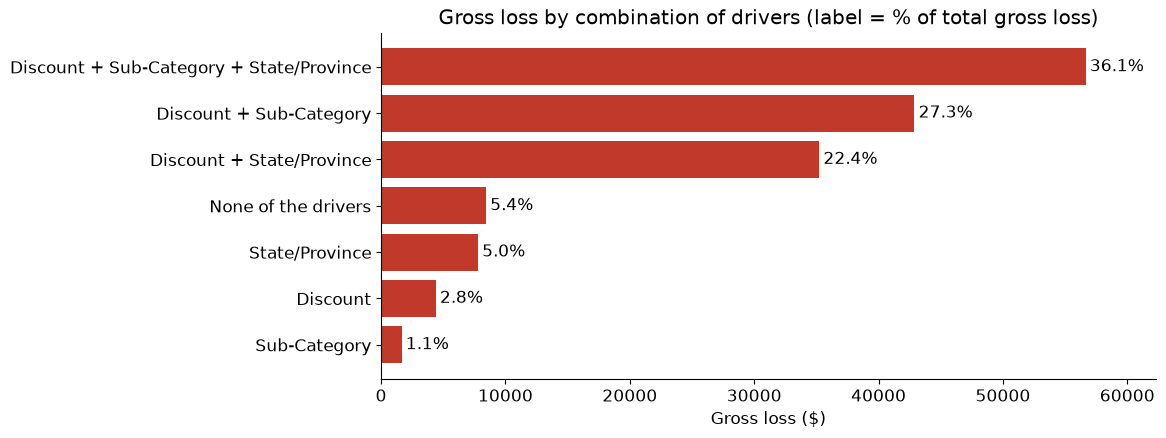

In [17]:
overlap = loss_drivers.overlap_table(df, drivers)
display(overlap)

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(overlap.index, -overlap["gross_loss"], color=NEGATIVE)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{p:.1f}%" for p in overlap["loss_share_pct"]], padding=3)
ax.margins(x=0.1)
ax.set(title="Gross loss by combination of drivers (label = % of total gross loss)", xlabel="Gross loss ($)")
plt.show()

**Step 4 – are product and place independent of discounts?** For each non-discount driver: how much of its loss sits on deep-discount lines, and what its loss rate is *without* deep discounts, inside the group and elsewhere.

In [18]:
indep = loss_drivers.independence_check(df, drivers)
indep.T

driver,"Sub-Category: Binders, Tables, Machines","State/Province: Texas, Ohio, Pennsylvania, Illinois"
deep_discount_rows_in_group_pct,42.59,41.65
deep_discount_rows_elsewhere_pct,6.91,4.70
group_loss_on_deep_discount_pct,98.37,92.18
loss_rate_in_group_no_deep_pct,2.89,14.61
loss_rate_elsewhere_no_deep_pct,6.52,4.31
rows_in_group_no_deep,"1,143.00","1,478.00"


## 8. Sizing the discount lever (supporting question 3)

Discount is the only lever that can be sized with this data. The scenario caps every discount at `HIGH_DISCOUNT`. Sales = list price × quantity × (1 − discount), so a lower discount raises the price. **Assumptions:** list prices and costs stay the same, and the real drop in volume is unknown, so a range is shown (from "no sales lost" to "all deep-discount sales lost"). This is an illustration, not a forecast.

,volume_lost_pct,profit,gain
scenario,,,
Current,0.00,"292,296.81",0.00
"Cap at 20%, 0% of deep-discount sales lost",0.00,"512,511.39","220,214.57"
"Cap at 20%, 25% of deep-discount sales lost",25.00,"491,462.91","199,166.10"
"Cap at 20%, 50% of deep-discount sales lost",50.00,"470,414.44","178,117.63"
"Cap at 20%, 75% of deep-discount sales lost",75.00,"449,365.97","157,069.16"
"Cap at 20%, 100% of deep-discount sales lost",100.00,"428,317.50","136,020.69"


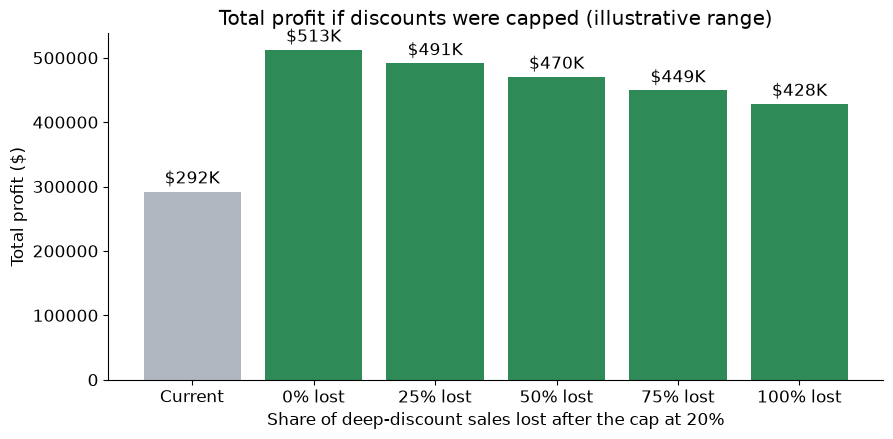

In [19]:
scen = loss_drivers.discount_cap_scenario(df)
display(scen)

fig, ax = plt.subplots(figsize=(10, 4.5))
labels = ["Current"] + [f"{v:.0%} lost" for v in loss_drivers.CAP_VOLUME_LOSS]
bars = ax.bar(labels, scen["profit"], color=[NEUTRAL] + ["seagreen"] * len(loss_drivers.CAP_VOLUME_LOSS))
ax.bar_label(bars, labels=[money(p) for p in scen["profit"]], padding=3)
ax.set(title="Total profit if discounts were capped (illustrative range)",
       xlabel=f"Share of deep-discount sales lost after the cap at {HIGH_DISCOUNT:.0%}", ylabel="Total profit ($)")
plt.show()

## 9. Limitations

The first check is about the dates in the data.

In [20]:
last = df["Order Date"].max()
after_today = (df["Order Date"] > pd.Timestamp.today()).sum()
print(f"Orders run from {df['Order Date'].min():%Y-%m-%d} to {last:%Y-%m-%d}; {after_today:,} order lines are dated after today.")

Orders run from 2023-01-03 to 2026-12-30; 595 order lines are dated after today.


- **Missing data.** The dataset has no store, returns or customer-satisfaction columns, so those parts of supporting questions 1 and 2 cannot be answered. Region, state and country are used instead of stores.
- **Cost.** `Product Cost` is derived (`Sales - Profit`). Returns, shipping and overhead are not in the data.
- **Association, not cause.** The data is observational: discounts may have been given to products that were already weak.
- **Dates.** If the order dates after today are not real, check whether the data is simulated before using the monthly trend.
- **Small samples.** Canada has few order lines, and some states are small (the state chart leaves out those under the minimum number of lines).
- **Analyst choices.** The 20% "deep discount" cut and the 60% coverage rule are choices. The cut is tested in section 6; the coverage rule was not re-tested.
- **Scenario.** The discount cap assumes constant list prices and costs and has no demand model.

## 10. Summary of key findings

All numbers below are calculated from the data above.

In [21]:
print(f"- Gross loss: {money(-gross_loss)} ({-gross_loss / gross_gain:.0%} of gross gains). {df['is_loss'].mean():.1%} of order lines lose money.")
print(f"- Lowest-margin category: {cat.index[0]} ({cat['margin_pct'].iloc[0]:.1f}%). Lowest-margin region: {region.index[0]} ({region['margin_pct'].iloc[0]:.1f}%).")
print("- Lowest-margin states (with enough data): " + ", ".join(f"{s} ({m:.0f}%)" for s, m in states["margin_pct"].head(3).items()) + ".")
for i, (label, row) in enumerate(ci.iterrows(), start=1):
    print(f"- Driver {i}: {label}: {row['row_share_pct']:.1f}% of order lines, {row['loss_share_pct']:.1f}% of gross loss "
          f"(95% interval {row['loss_share_lo']:.1f}-{row['loss_share_hi']:.1f}%).")
for label, row in indep.iterrows():
    print(f"- {label}: {row['group_loss_on_deep_discount_pct']:.0f}% of its loss is on deep-discount lines. Without deep discounts its loss rate is "
          f"{row['loss_rate_in_group_no_deep_pct']:.1f}% inside the group and {row['loss_rate_elsewhere_no_deep_pct']:.1f}% elsewhere.")
cap = scen.iloc[1:]
print(f"- Capping discounts at {HIGH_DISCOUNT:.0%} would change profit by {money(cap['gain'].min())} to {money(cap['gain'].max())} "
      f"(illustrative; depends on how many sales are lost).")

- Gross loss: $157K (35% of gross gains). 18.6% of order lines lose money.
- Lowest-margin category: Furniture (2.6%). Lowest-margin region: Central (7.9%).
- Lowest-margin states (with enough data): Ohio (-22%), Colorado (-20%), Tennessee (-17%).
- Driver 1: Deep discount (>20%): 13.9% of order lines, 88.6% of gross loss (95% interval 85.5-91.0%).
- Driver 2: Sub-Category: Binders, Tables, Machines: 19.5% of order lines, 64.4% of gross loss (95% interval 58.1-70.0%).
- Driver 3: State/Province: Texas, Ohio, Pennsylvania, Illinois: 24.8% of order lines, 63.5% of gross loss (95% interval 55.4-71.0%).
- Sub-Category: Binders, Tables, Machines: 98% of its loss is on deep-discount lines. Without deep discounts its loss rate is 2.9% inside the group and 6.5% elsewhere.
- State/Province: Texas, Ohio, Pennsylvania, Illinois: 92% of its loss is on deep-discount lines. Without deep discounts its loss rate is 14.6% inside the group and 4.3% elsewhere.
- Capping discounts at 20% would change prof

Interpretation and recommendations are developed in the technical report and the final presentation.